In [19]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


torch.set_num_threads(2)
DATA_PATH = Path('/Users/zhangxinxiang/Desktop/DS4420 Project/Charles_River_Data /daily_merged.csv')

In [20]:
df = pd.read_csv(DATA_PATH, parse_dates=['date']).sort_values('date').reset_index(drop=True)
use = df[df.date.between('1990-01-01','2025-12-31')].copy()

In [21]:
for k in range(1,8):
    for src,prefix in [('discharge_cfs_mean','flow'),('precip_in','precip'),('tmean_f','temp'),('snowfall_in','snow')]:
        use[f'{prefix}_lag_{k}'] = use[src].shift(k)
use = use.dropna(subset=[f'flow_lag_{k}' for k in range(1,8)]).copy()
flow_features = [f'flow_lag_{k}' for k in range(1,8)] + ['doy_sin','doy_cos']
weather_features = [f'{v}_lag_{k}' for v in ('precip','temp','snow') for k in range(1,8)]
all_features = flow_features + weather_features
train = use[use.date < '2017-01-01'].copy()
val = use[use.date.between('2017-01-01','2020-12-31')].copy()
test = use[use.date.between('2021-01-01','2025-12-31')].copy()
assert max(train.date) < min(val.date) < max(val.date) < min(test.date)

In [22]:
def prepare(features):
    med = train[features].median().fillna(0)
    Xtrain0 = train[features].fillna(med)
    scaler = StandardScaler().fit(Xtrain0)
    def x(part):
        return torch.tensor(scaler.transform(part[features].fillna(med)),dtype=torch.float32)
    def y(part):
        return torch.tensor(np.log1p(part['discharge_cfs_mean'].to_numpy()), dtype=torch.float32).reshape(-1,1)
    return x(train),y(train),x(val),y(val),x(test),scaler,med

class MLP(nn.Module):
    def __init__(self, n_features):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(n_features,32),nn.ReLU(),
                                 nn.Linear(32,16),nn.ReLU(),nn.Linear(16,1))
    def forward(self,x): return self.net(x)

def train_model(features, max_epochs=140, patience=16):
    Xt,yt,Xv,yv,Xe,scaler,med = prepare(features)
    model = MLP(len(features))
    opt = torch.optim.Adam(model.parameters(),lr=0.003,weight_decay=0.0001)
    criterion=nn.MSELoss()
    best=float('inf'); wait=0; best_state=None; losses=[]
    for epoch in range(max_epochs):
        model.train()
        ix = torch.randperm(len(Xt))
        for b in ix.split(512):
            opt.zero_grad()
            loss=criterion(model(Xt[b]),yt[b])
            loss.backward()
            opt.step()
        model.eval()
        with torch.no_grad():
            tr=criterion(model(Xt),yt).item()
            va=criterion(model(Xv),yv).item()
        losses.append((tr,va))
        if va < best-1e-5:
            best=va; wait=0
            best_state={k:v.detach().clone() for k,v in model.state_dict().items()}
        else:
            wait+=1
            if wait>=patience:break
    model.load_state_dict(best_state)
    model.eval()
    with torch.no_grad():
        pred=np.expm1(model(Xe).numpy().reshape(-1))
    pred=np.maximum(pred,0)
    return dict(model=model,pred=pred,losses=np.asarray(losses),scaler=scaler,medians=med,features=features)

flow_only=train_model(flow_features)
flow_weather=train_model(all_features)


In [23]:
y_true=test['discharge_cfs_mean'].to_numpy()
preds={
    'Persistence (yesterday)':test['flow_lag_1'].to_numpy(),
    'MLP: flow + season':flow_only['pred'],
    'MLP: flow + weather + season':flow_weather['pred']
}
rows=[]
for name,pred in preds.items():
    rows.append({'Model':name,
                 'MAE (cfs)':mean_absolute_error(y_true,pred),
                 'RMSE (cfs)':np.sqrt(mean_squared_error(y_true,pred)),
                 'R²':r2_score(y_true,pred)})
results=pd.DataFrame(rows).sort_values('MAE (cfs)').reset_index(drop=True)
print(results.round(3).to_string(index=False))


                       Model  MAE (cfs)  RMSE (cfs)    R²
     Persistence (yesterday)     27.691      57.304 0.957
MLP: flow + weather + season     30.571      61.669 0.950
          MLP: flow + season     33.123      90.865 0.891


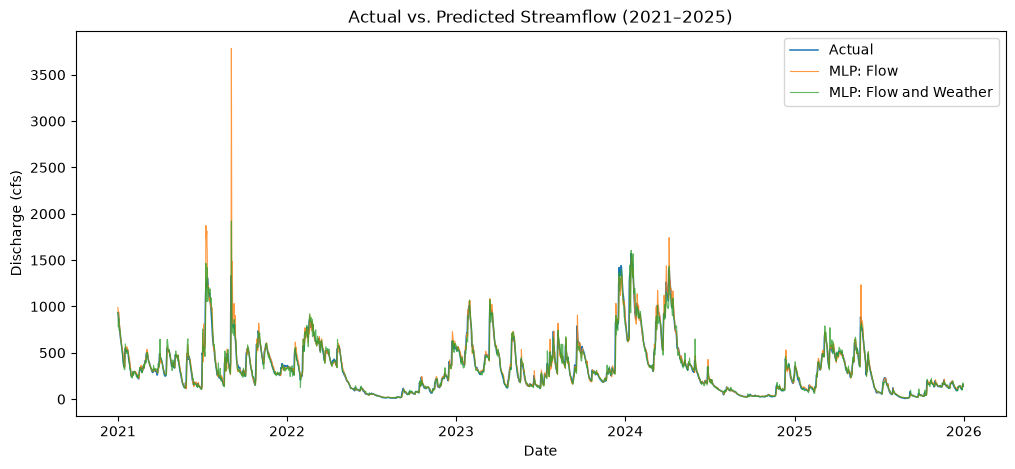

In [24]:
out_dir = Path('mlp_outputs')
out_dir.mkdir(exist_ok=True)

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(test.date, y_true, label='Actual', linewidth=1.1)
ax.plot(test.date, flow_only['pred'], label='MLP: Flow', alpha=0.8, linewidth=0.8)
ax.plot(test.date, flow_weather['pred'], label='MLP: Flow and Weather', alpha=0.75, linewidth=0.8)

ax.set_title('Actual vs. Predicted Streamflow (2021–2025)')
ax.set_xlabel('Date')
ax.set_ylabel('Discharge (cfs)')
ax.legend()

fig.savefig(out_dir / 'mlp_predictions.png', dpi=170, bbox_inches='tight')
plt.show()